MLE Logistic Regression
-----------------------
Accuracy: 0.9385964912280702

Confusion Matrix
[[42  1]
 [ 6 65]]

Classification Report
              precision    recall  f1-score   support

           0       0.88      0.98      0.92        43
           1       0.98      0.92      0.95        71

    accuracy                           0.94       114
   macro avg       0.93      0.95      0.94       114
weighted avg       0.94      0.94      0.94       114


MAP using L1 Regularization
---------------------------
Accuracy: 0.9736842105263158

MAP using L2 Regularization
---------------------------
Accuracy: 0.9736842105263158

Accuracy Comparison:
      Model  Accuracy
0       MLE  0.938596
1  MAP (L1)  0.973684
2  MAP (L2)  0.973684

Top 10 Feature Coefficients:
                  Feature         MLE  MAP (L1)  MAP (L2)
0             mean radius    9.433096  0.000000 -0.431904
1            mean texture  -16.986388  0.000000 -0.387326
2          mean perimeter   40.020926  0.000000 -0

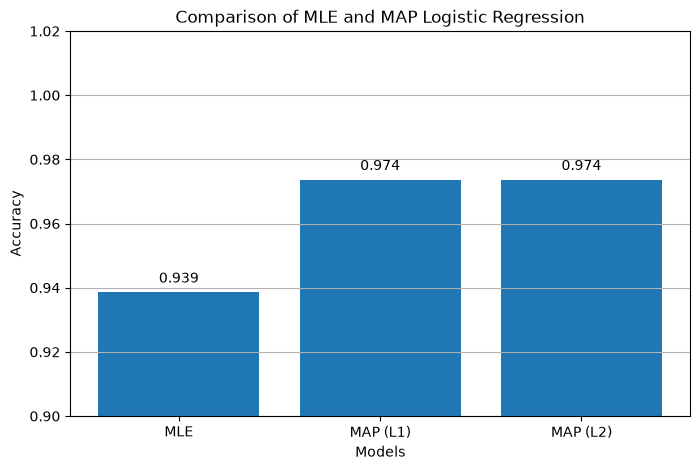

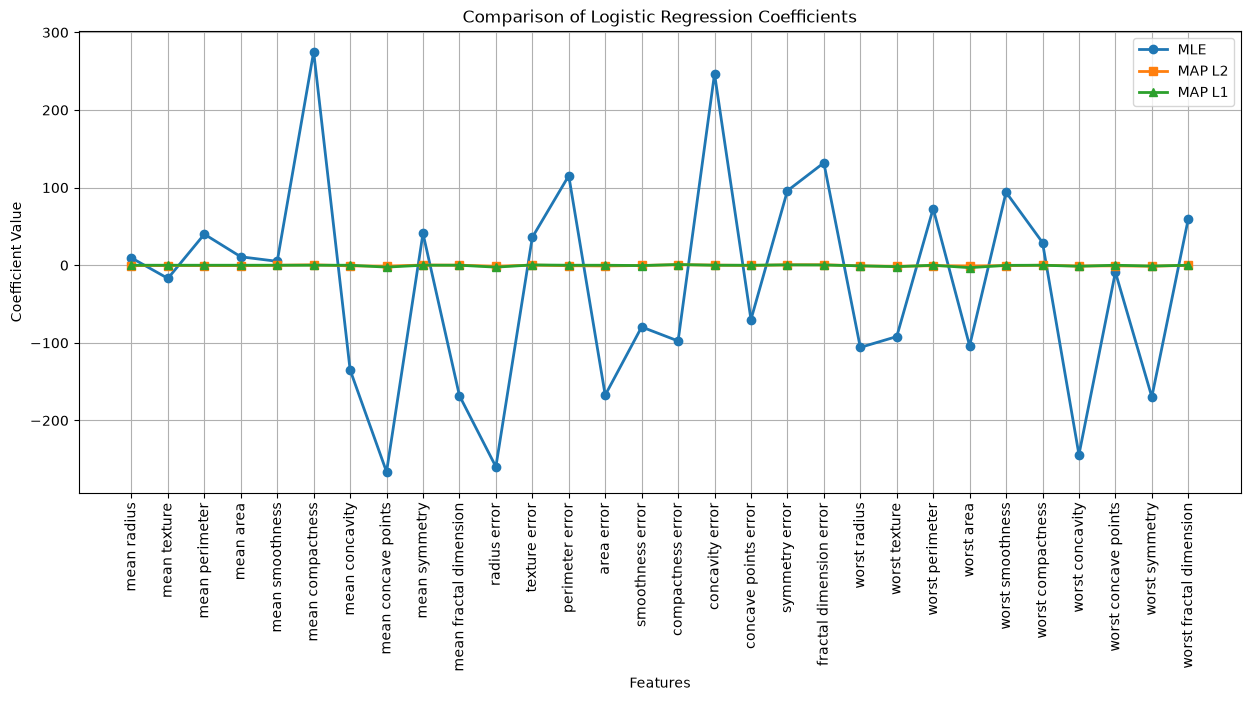

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


mle_model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=5000)
mle_model.fit(X_train, y_train)
y_pred_mle = mle_model.predict(X_test)

print("MLE Logistic Regression")
print("-----------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_mle))
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_mle))
print("\nClassification Report")
print(classification_report(y_test, y_pred_mle))


map_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=5000)
map_l1.fit(X_train, y_train)
y_pred_l1 = map_l1.predict(X_test)

print("\nMAP using L1 Regularization")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_l1))


map_l2 = LogisticRegression(penalty='l2', solver='lbfgs', C=1.0, max_iter=5000)
map_l2.fit(X_train, y_train)
y_pred_l2 = map_l2.predict(X_test)

print("\nMAP using L2 Regularization")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_l2))

comparison = pd.DataFrame({
    "Model": ["MLE", "MAP (L1)", "MAP (L2)"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_mle),
        accuracy_score(y_test, y_pred_l1),
        accuracy_score(y_test, y_pred_l2)
    ]
})
print("\nAccuracy Comparison:")
print(comparison)


coef = pd.DataFrame({
    "Feature": data.feature_names,
    "MLE": mle_model.coef_[0],
    "MAP (L1)": map_l1.coef_[0],
    "MAP (L2)": map_l2.coef_[0]
})
print("\nTop 10 Feature Coefficients:")
print(coef.head(10))


models = ["MLE", "MAP (L1)", "MAP (L2)"]
accuracies = [
    accuracy_score(y_test, y_pred_mle),
    accuracy_score(y_test, y_pred_l1),
    accuracy_score(y_test, y_pred_l2)
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Comparison of MLE and MAP Logistic Regression")

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.003, f"{acc:.3f}", ha='center')

plt.ylim(0.9, 1.02)
plt.grid(axis='y')
plt.show()


features = coef["Feature"]

plt.figure(figsize=(15, 6))
plt.plot(features, coef["MLE"], marker='o', linewidth=2, label='MLE')
plt.plot(features, coef["MAP (L2)"], marker='s', linewidth=2, label='MAP L2')
plt.plot(features, coef["MAP (L1)"], marker='^', linewidth=2, label='MAP L1')

plt.xticks(rotation=90)
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.title("Comparison of Logistic Regression Coefficients")
plt.legend()
plt.grid(True)
plt.show()